# Group 9: Dataset card review (Disha)

This notebook **looks at the images for you** and **writes the finished `docs/dataset_card.md`**.
It needs the main notebook to have been run first (audit + split), because it reads those results.

**How to run:** Runtime → **Run all**. No GPU needed. About 10 to 20 minutes (most of it is the face check).

It does three checks:
- **A.** Product vs Real World near-duplicates: same photo or not?
- **B.** Duplicate groups inside Product with different labels: same picture labelled twice?
- **C.** Faces of people in Real World and Product (automatic detector).

Then it writes the dataset card with every number filled in.
**One thing needs you:** set `ACCESS_DATE` in cell 2 (or leave it, and it stays as a TODO in the card).

In [1]:
# 1. Connect Drive, go into your project folder, install packages
BASE = "/content/drive/MyDrive/DeepLearning"     # the folder that holds group9
from google.colab import drive
drive.mount('/content/drive')
import os, sys
os.chdir(f"{BASE}/group9")
sys.path.insert(0, os.getcwd())   # so `from src...` works
!pip install -q datasets imagehash
print("Working in", os.getcwd())

Mounted at /content/drive
Working in /content/drive/MyDrive/DeepLearning/group9


In [2]:
# 2. Settings (only ACCESS_DATE needs you)
# When was the dataset first downloaded? The proposal says 24 Oct 2026, the Colab printout 25 Oct.
# Write the correct one, e.g. "25 October 2026". Leaving None puts a TODO in the card.
ACCESS_DATE = "7 November 2026"

SAME_PHOTO_CORR = 0.95   # pixel correlation at or above this (and same shape) = "same photo"
CONFIG = None            # leave as None
CARD_PATH = None         # leave as None (writes docs/dataset_card.md)

In [3]:
# 3. Load the audit results and the dataset (about 1 minute)
import json, math
from collections import Counter
from pathlib import Path

import cv2
import imagehash
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import ImageDraw

from src.data.officehome import load_config, load_officehome, repo_path

cfg = load_config(CONFIG)
AUD = repo_path(cfg["paths"]["audit_dir"])
SPL = repo_path(cfg["paths"]["splits_dir"])
OUT = repo_path(cfg["paths"]["outputs_dir"]) / "audit" / "review"   # contact sheets (not committed)
OUT.mkdir(parents=True, exist_ok=True)
CARD = Path(CARD_PATH) if CARD_PATH else repo_path("docs/dataset_card.md")
SRC, TGT = cfg["data"]["source_domain"], cfg["data"]["target_domain"]

a = json.load(open(AUD / "summary.json"))
s = json.load(open(SPL / "split_summary.json"))
man = pd.read_csv(SPL / "product_split.csv")
split_of = dict(zip(man.row_id, man.split))

ds = load_officehome(cfg)
domains = np.array(ds["domain"], dtype=object)

def img(r):
    return ds[int(r)]["image"].convert("RGB")

def pixel_corr(x, y):
    """Correlation of two images shrunk to 64x64 grey (1.0 = identical picture)."""
    u = np.asarray(x.convert("L").resize((64, 64)), dtype=np.float32).ravel()
    v = np.asarray(y.convert("L").resize((64, 64)), dtype=np.float32).ravel()
    u, v = u - u.mean(), v - v.mean()
    d = math.sqrt(float((u * u).sum() * (v * v).sum()))
    return float((u * v).sum() / d) if d > 0 else 0.0

def same_shape(x, y):
    return abs(math.log((x.width / x.height) / (y.width / y.height))) < 0.1

def sheet(rows, title, fname, cols=None):
    """rows = list of lists of (PIL image, caption). Shows the sheet and saves it."""
    if not rows:
        print(f"{title}: nothing to show.")
        return
    cols = cols or max(len(r) for r in rows)
    fig, axes = plt.subplots(len(rows), cols, figsize=(2.6 * cols, 2.9 * len(rows)), squeeze=False)
    for i, r in enumerate(rows):
        for j in range(cols):
            ax = axes[i][j]
            ax.axis("off")
            if j < len(r):
                ax.imshow(r[j][0])
                ax.set_title(r[j][1], fontsize=7)
    fig.suptitle(title, fontsize=11)
    fig.tight_layout()
    fig.savefig(OUT / fname, dpi=80)
    plt.show()

print("Loaded:", len(ds), "images;", len(man), "Product images in the split.")

README.md:   0%|          | 0.00/5.94k [00:00<?, ?B/s]

data/train-00000-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  249MB            

data/train-00000-of-00003.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  119MB            

data/train-00001-of-00003.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  791MB            

data/train-00002-of-00003.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/15588 [00:00<?, ? examples/s]

Loaded: 15588 images; 4439 Product images in the split.


## A. Product vs Real World
A pair is called **same photo** when the shrunken images are almost identical (correlation ≥ 0.95) and have the same shape.

verdict
similar, different photo    12
same photo                   2


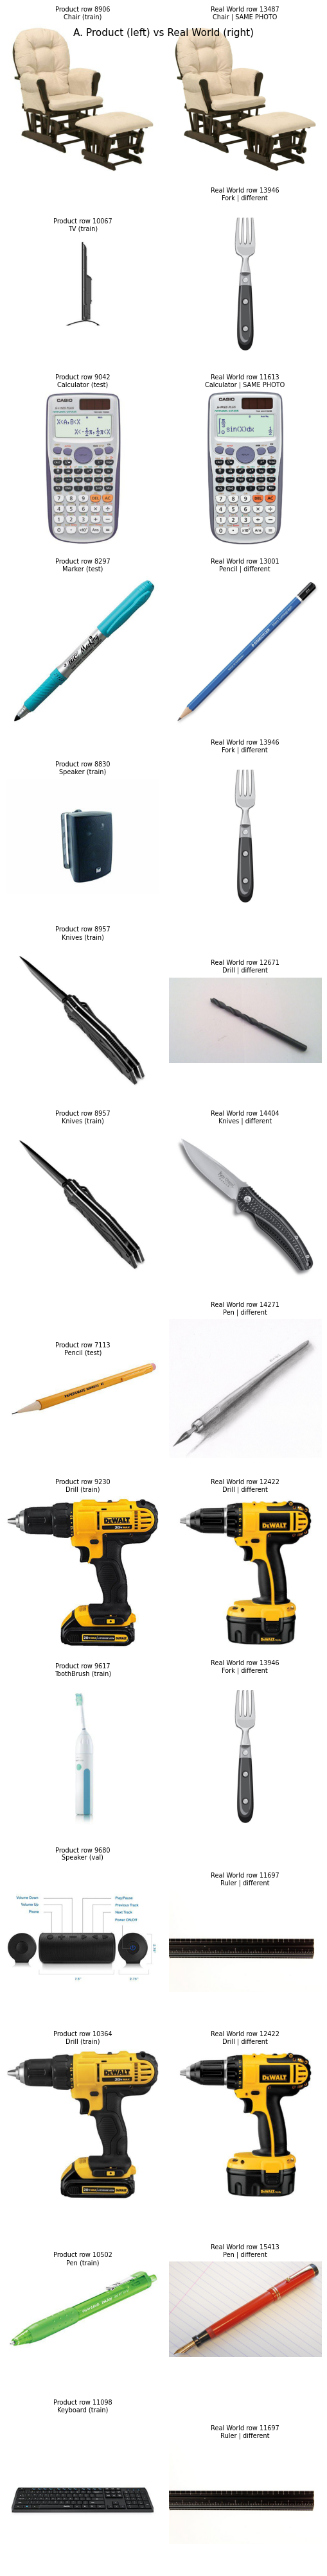

In [4]:
# 4. Check A: Product vs Real World near-duplicates. Are they the same photo?
x = pd.read_csv(AUD / "cross_domain_near_dup_pairs.csv")
rows, pics = [], []
for r in x.to_dict("records"):
    A, B = img(r["product_row"]), img(r["realworld_row"])
    c = pixel_corr(A, B)
    same = c >= SAME_PHOTO_CORR and same_shape(A, B)
    rows.append({**r,
                 "pixel_corr": round(c, 3),
                 "dhash_distance": int(imagehash.dhash(A) - imagehash.dhash(B)),
                 "same_class": r["product_class"] == r["realworld_class"],
                 "product_split": split_of.get(r["product_row"], "not in split"),
                 "verdict": "same photo" if same else "similar, different photo"})
    pics.append([(A, f"Product row {r['product_row']}\n{r['product_class']} ({split_of.get(r['product_row'], '-')})"),
                 (B, f"Real World row {r['realworld_row']}\n{r['realworld_class']} | {'SAME PHOTO' if same else 'different'}")])
cols = list(x.columns) + ["pixel_corr", "dhash_distance", "same_class", "product_split", "verdict"]
xr = pd.DataFrame(rows, columns=cols)
xr.to_csv(AUD / "cross_domain_review.csv", index=False)
print(xr.verdict.value_counts().to_string() if len(xr) else "No cross-domain pairs.")
sheet(pics, "A. Product (left) vs Real World (right)", "A_cross_domain.jpg")

## B. Same picture, different labels

16 groups, 38 images
verdict
same image, two labels              10
similar images, different labels     6

Class combinations:
classes
Computer / Laptop            4
File_Cabinet / Folder        4
Pencil / Ruler               1
Calendar / Notebook          1
Ruler / Screwdriver          1
Fork / Mop / TV              1
Bed / Laptop                 1
Desk_Lamp / Lamp_Shade       1
Speaker / TV / ToothBrush    1
Pen / Ruler                  1


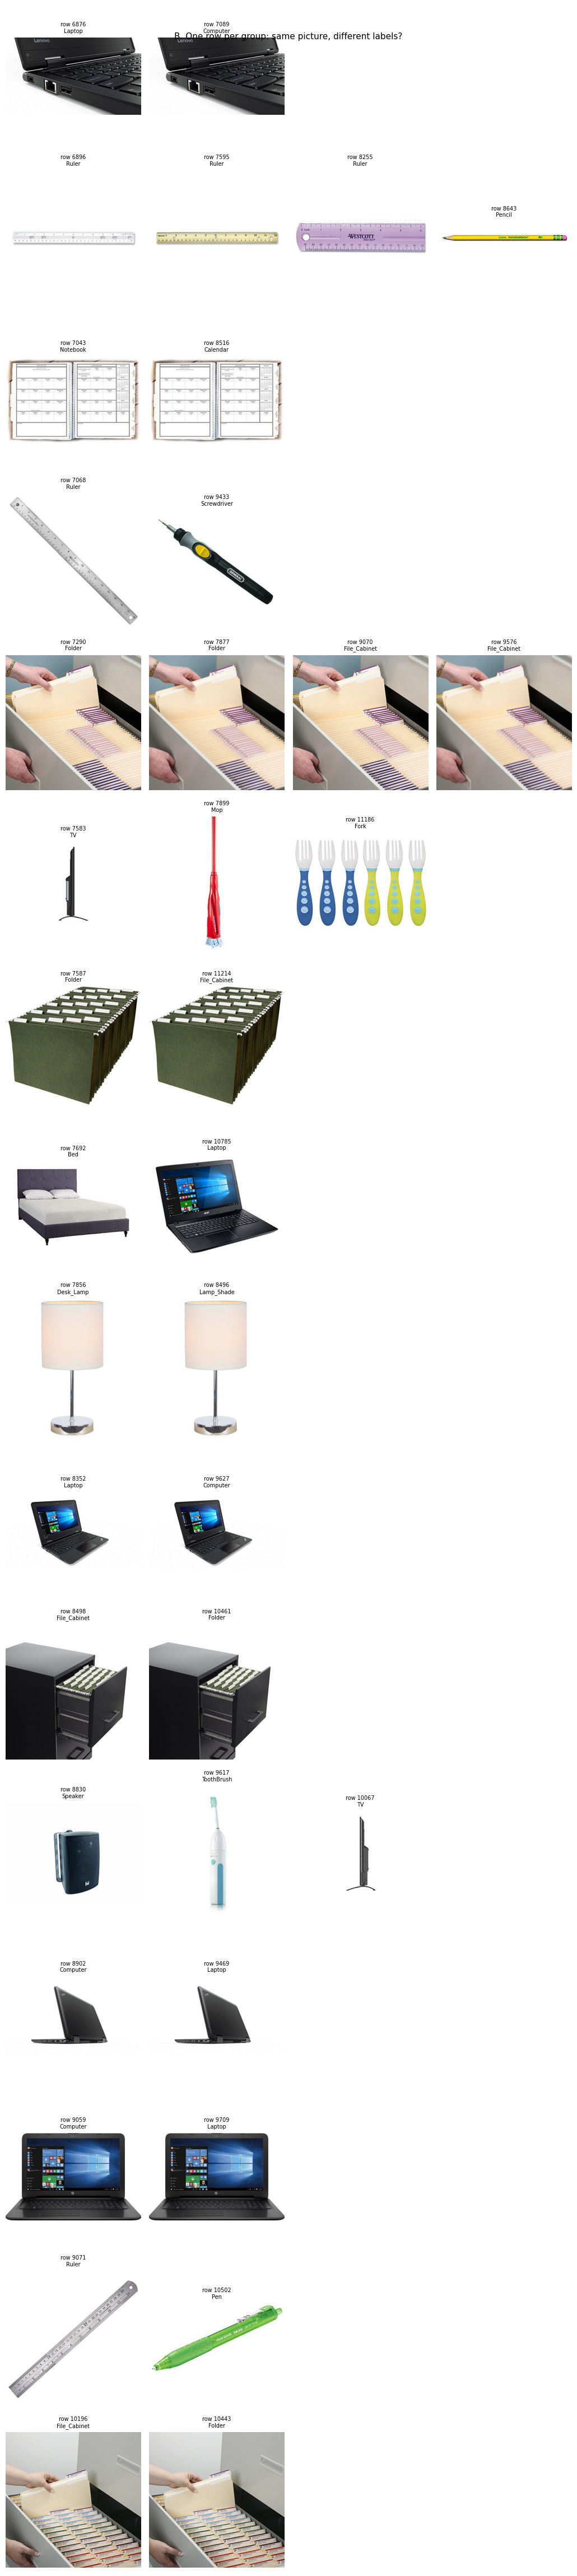

In [5]:
# 5. Check B: near-duplicate groups inside Product that carry DIFFERENT labels
g = pd.read_csv(AUD / "product_dup_groups.csv")
multi = g[g.group_size > 1]
conf_ids = [gid for gid, m in multi.groupby("dup_group") if m.label.nunique() > 1]
crow, pics = [], []
for gid in conf_ids:
    m = multi[multi.dup_group == gid]
    ims = {r: img(r) for r in m.row_id}
    best = max(pixel_corr(ims[r1], ims[r2])
               for r1, l1 in zip(m.row_id, m.label) for r2, l2 in zip(m.row_id, m.label) if l1 < l2)
    verdict = "same image, two labels" if best >= SAME_PHOTO_CORR else "similar images, different labels"
    crow.append({"dup_group": gid, "rows": " ".join(map(str, m.row_id)), "n_images": len(m),
                 "classes": " / ".join(sorted(set(m["class"]))), "split": split_of.get(int(m.row_id.iloc[0]), "-"),
                 "max_corr_between_labels": round(best, 3), "verdict": verdict})
    pics.append([(ims[r], f"row {r}\n{c}") for r, c in zip(m.row_id, m["class"])])
cr = pd.DataFrame(crow, columns=["dup_group", "rows", "n_images", "classes", "split", "max_corr_between_labels", "verdict"])
cr.to_csv(AUD / "conflicting_label_review.csv", index=False)
print(len(cr), "groups,", int(cr.n_images.sum()) if len(cr) else 0, "images")
if len(cr):
    print(cr.verdict.value_counts().to_string())
    print("\nClass combinations:\n" + cr.classes.value_counts().to_string())
sheet(pics, "B. One row per group: same picture, different labels?", "B_conflicting_labels.jpg")

## C. People in the images

  Real World: 1000/4357
  Real World: 2000/4357
  Real World: 3000/4357
  Real World: 4000/4357
  Product: 1000/4439
  Product: 2000/4439
  Product: 3000/4439
  Product: 4000/4439
Images with a detected face: {'Real World': 275, 'Product': 137}
Most common classes: {'Bike': 21, 'Flowers': 19, 'Telephone': 18, 'Alarm_Clock': 16, 'Candles': 16, 'Flipflops': 15, 'Calculator': 15, 'Toys': 14}


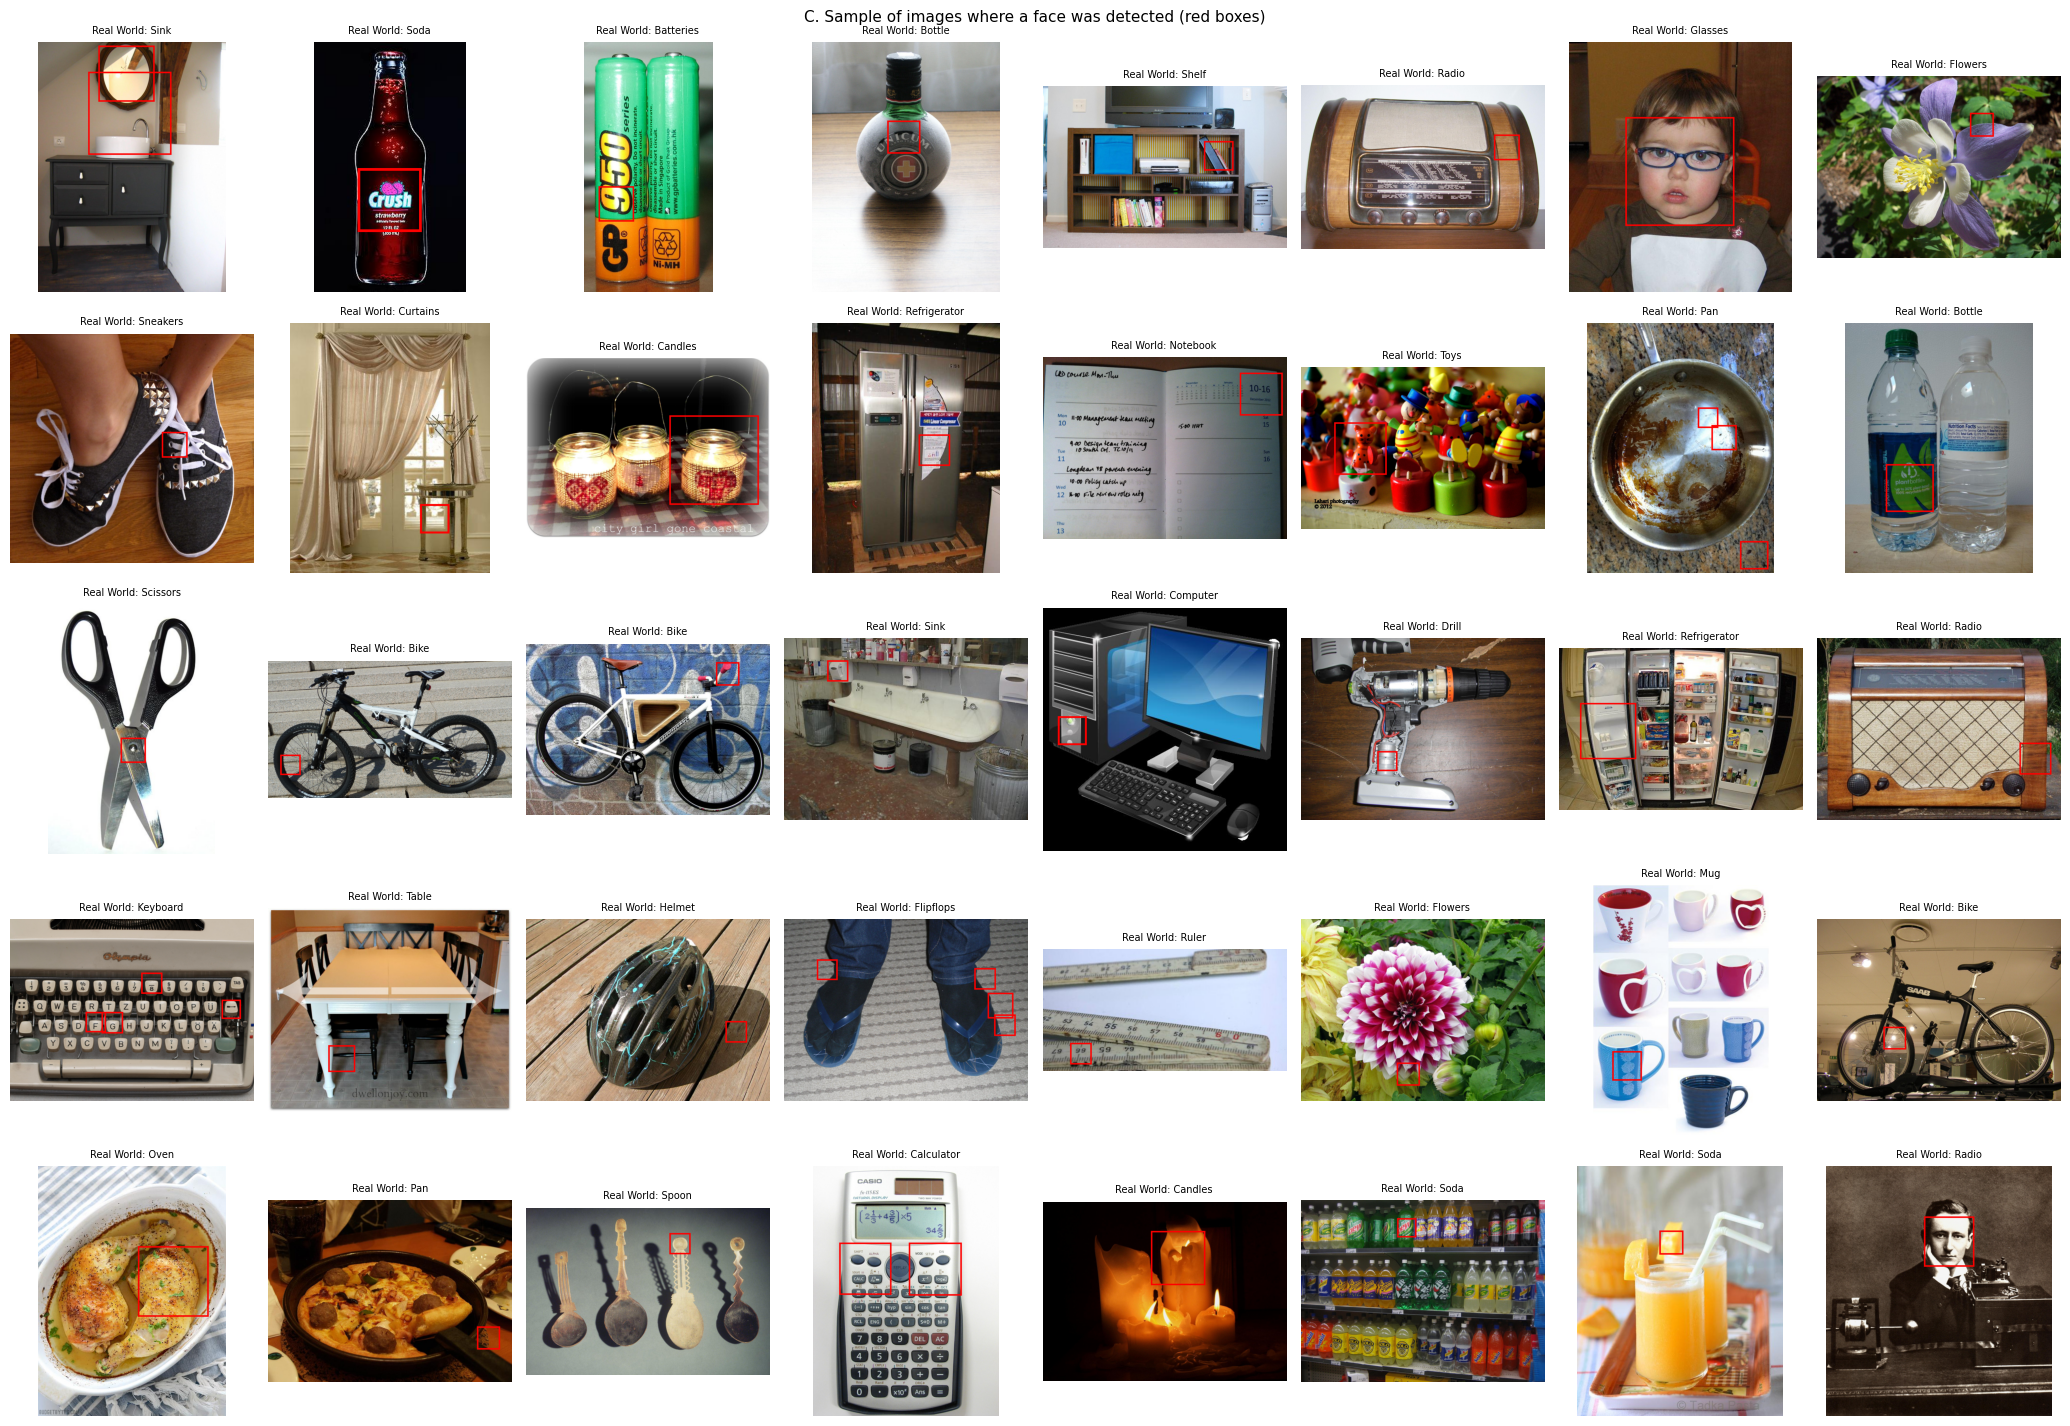

In [6]:
# 6. Check C: automatic face detection on Real World and Product (about 5 to 15 minutes; progress prints every 1000 images)
# OpenCV's frontal-face detector. It is approximate: it misses side views and has some false alarms.
XML = "haarcascade_frontalface_default.xml"
cascade = cv2.CascadeClassifier(cv2.data.haarcascades + XML)
if cascade.empty():   # some OpenCV builds ship without the model file: fetch it from the OpenCV repo
    import urllib.request
    local = OUT / XML
    if not local.exists():
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/opencv/opencv/4.x/data/haarcascades/{XML}", local)
    cascade = cv2.CascadeClassifier(str(local))
assert not cascade.empty(), "Could not load the face detector"
face_rows, face_pics = [], []
readable = {TGT: pd.read_csv(SPL / s["targets"][TGT]["file"]).row_id.to_numpy(),   # unreadable files already left out
            SRC: man.row_id.to_numpy()}
for dom in (TGT, SRC):
    rows_d = readable[dom]
    for k, (r, ex) in enumerate(zip(rows_d, ds.select(rows_d))):
        im = ex["image"].convert("RGB")
        scale = min(1.0, 640 / max(im.size))
        small = im.resize((max(1, round(im.width * scale)), max(1, round(im.height * scale)))) if scale < 1 else im
        gray = cv2.cvtColor(np.asarray(small), cv2.COLOR_RGB2GRAY)
        found = cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=6, minSize=(40, 40))
        if len(found):
            face_rows.append({"row_id": int(r), "domain": dom, "class": ds.features["label"].names[ex["label"]],
                              "faces": len(found)})
            if len(face_pics) < 40:
                d = ImageDraw.Draw(small)
                for (fx, fy, fw, fh) in found:
                    d.rectangle([fx, fy, fx + fw, fy + fh], outline=(255, 0, 0), width=4)
                face_pics.append((small, f"{dom}: {face_rows[-1]['class']}"))
        if (k + 1) % 1000 == 0:
            print(f"  {dom}: {k + 1}/{len(rows_d)}")
fr = pd.DataFrame(face_rows, columns=["row_id", "domain", "class", "faces"])
fr.to_csv(AUD / "faces_detected.csv", index=False)
face_counts = {dom: int((fr.domain == dom).sum()) for dom in (TGT, SRC)}
print("Images with a detected face:", face_counts)
if len(fr):
    print("Most common classes:", fr["class"].value_counts().head(8).to_dict())
sheet([face_pics[i:i + 8] for i in range(0, len(face_pics), 8)],
      "C. Sample of images where a face was detected (red boxes)", "C_faces.jpg", cols=8)

## Write the dataset card

In [7]:
# 7. Write docs/dataset_card.md with every number filled in
cc = a["count_checks"]
pc = a["product_class_counts"]
nd = a["product_near_duplicates"]
sizes = pd.read_csv(AUD / "image_size_stats.csv")
flags = pd.read_csv(AUD / "flagged_samples.csv")
flags["reasons"] = flags["reasons"].astype(str)
reason_n = {k: int(flags.reasons.str.contains(k).sum()) for k in ["unreadable", "mode", "tiny", "aspect ratio"]}
modes = flags.reasons.str.extract(r"mode (\w+)")[0].value_counts().to_dict()
split_n = {k: v["found"] for k, v in s["checks"]["counts"].items()}
pcs = pd.DataFrame(s["per_class_split_counts"]).T.fillna(0).astype(int)
b = s["budgets"]
seeds = list(b)
bs = b[seeds[0]]["sizes"]
same_budgets = all(b[k]["sizes"] == bs for k in seeds)
min_b10 = min(b[k]["min_images_per_class_b10"] for k in seeds)
tgt = s["targets"]
class_table = (AUD / "class_counts.md").read_text()

n_same = int((xr.verdict == "same photo").sum()) if len(xr) else 0
same_x = xr[xr.verdict == "same photo"] if len(xr) else xr
same_split = same_x.product_split.value_counts().to_dict() if len(same_x) else {}
n_conf_same = int((cr.verdict == "same image, two labels").sum()) if len(cr) else 0
conf_classes = ", ".join(f"{k} ({v})" for k, v in cr.classes.value_counts().items()) if len(cr) else "none"
conf_splits = cr.split.value_counts().to_dict() if len(cr) else {}
empty = a["classes"]["classes_with_zero_images"]
empty_note = "no class is empty in any domain" if not empty else "classes with no images: " + "; ".join(f"{d}: {', '.join(c)}" for d, c in empty.items())
val_note = (f"at the 10% budget the {split_n['val']} validation images outnumber the {bs['b10']} training images, "
            "so validation-loss selection has more data to judge with than the model had to learn from")
access = ACCESS_DATE or "TODO: confirm (24 Oct 2026 in the proposal, 25 Oct 2026 in the Colab printout)"

def fmt(d):
    return ", ".join(f"{k}: {v}" for k, v in d.items()) if d else "none"

if n_same:
    cross_note = (f"{n_same} are the same photo (Product copy in: {fmt(same_split)}). These Real World images are not "
                  f"strictly unseen, but they are {n_same} of {tgt[TGT]['n']:,} target images "
                  f"({100 * n_same / max(1, tgt[TGT]['n']):.2f}%) and affect both selection rules equally, so they are "
                  "kept and reported as a limitation.")
else:
    cross_note = "none is the same photo (similar-looking objects only), so no Product-to-Real-World leakage was found."
if face_counts[TGT] + face_counts[SRC]:
    people_note = ("People appear only incidentally (for example, someone holding or using an object); no image is "
                   "labelled by person, and we do not identify, crop or redistribute anyone.")
else:
    people_note = "The detector found no faces (it can miss some)."

size_rows = "\n".join(
    f"| {r.domain} | {r.n:,} | {r.width_min}–{int(r.width_median)}–{r.width_max} | "
    f"{r.height_min}–{int(r.height_median)}–{r.height_max} | {r.non_rgb} |"
    for r in sizes.itertuples())

card = f"""# Dataset Card: Office-Home (Group 9)

*Owner: Disha Rawat. Numbers come from `results/data_audit/` and `configs/splits/split_summary.json`,
written by `src/data/audit.py`, `src/data/make_splits.py` and `notebooks/dataset_card_review.ipynb`.*

## 1. Source and version
| Item | Value |
|---|---|
| Dataset | Office-Home (Venkateswara et al., CVPR 2017) |
| Original source | https://www.hemanthdv.org/officeHomeDataset.html |
| Copy used | Hugging Face `{cfg["data"]["hf_name"]}` (Flower Labs) |
| Pinned revision | `{cfg["data"]["hf_revision"]}` (last changed 29 Aug 2024) |
| Format | Parquet; one split named `train` holding all {cc["total"]["found"]:,} images; columns `image`, `domain`, `label` |
| Download size | about 1.16 GB (about 1.3 GB loaded) |
| Accessed | {access} |
| Audit run | {a["run_at_utc"]} |

**Access:**
```python
from datasets import load_dataset
ds = load_dataset("{cfg["data"]["hf_name"]}", split="train",
                  revision="{cfg["data"]["hf_revision"]}")
```

## 2. License and intended use
- License on the hub: **other: fair-use notice** pointing to the original Office-Home website. It is not an open-source license.
- Use: research and teaching in this course only. The repository holds row IDs, labels, metric summaries and a few report figures, not the dataset.
- Citation: Venkateswara et al. (2017); the hub card also asks that Flower (Beutel et al., 2020) be cited when the Flower tooling is used.

## 3. Task, inputs and targets
- **Task:** 65-way single-label object classification.
- **Input:** one image, converted to RGB at load time, resized and cropped to 224 × 224, ImageNet-normalised.
- **Target:** integer label 0–64 (`Alarm_Clock` = 0 … `Webcam` = 64), stored as a `ClassLabel`.
- **Annotation format:** one class label per image; no boxes, no file names.
- **Image ID:** the row number in the pinned revision (`row_id`). It is stable only because the revision is pinned.

## 4. Domains and counts
| Domain | Proposal | Audit | Check | Role in this project |
|---|---|---|---|---|
| Product | {cc[SRC]["expected"]:,} | {cc[SRC]["found"]:,} | {cc[SRC]["status"]} | Source: train / validation / source test |
| Real World (`"Real World"`, with a space) | {cc[TGT]["expected"]:,} | {cc[TGT]["found"]:,} | {cc[TGT]["status"]} | Held-out target: final evaluation only |
| Art | {cc["Art"]["expected"]:,} | {cc["Art"]["found"]:,} | {cc["Art"]["status"]} | Optional extra target |
| Clipart | {cc["Clipart"]["expected"]:,} | {cc["Clipart"]["found"]:,} | {cc["Clipart"]["status"]} | Not used |
| **Total** | {cc["total"]["expected"]:,} | {cc["total"]["found"]:,} | {cc["total"]["status"]} | |

**Classes:** {a["classes"]["num_classes"]} classes ({a["classes"]["status"]}); {empty_note}.
**Class distribution (Product):** {pc["min"]} images ({pc["min_class"]}) to {pc["max"]} ({pc["max_class"]}) per class,
median {pc["median"]:g}. Full table in the appendix; figure `results/figures/product_class_distribution.png`.

**Image sizes** (width and height in pixels, min–median–max):

| Domain | Images | Width | Height | Non-RGB files |
|---|---|---|---|---|
{size_rows}

## 5. Splits (fixed once)
| Split | Images | Use |
|---|---|---|
| Product train | {split_n["train"]:,} | Training; nested label budgets |
| Product validation | {split_n["val"]:,} | Checkpoint selection (validation loss) and the LR pilot |
| Product test | {split_n["test"]:,} | In-domain reference |
| Real World | {tgt[TGT]["n"]:,} | Final evaluation only, after the 16 Nov freeze |

- Class-stratified with split seed **{s["split_seed"]}**; largest-remainder quotas make the totals exact.
  Every class has at least {int(pcs["val"].min())} validation and {int(pcs["test"].min())} test images.
- Near-duplicate groups (pHash Hamming distance ≤ {s["near_dup_hamming"]}) are kept inside one split;
  **{s["checks"]["duplicate_groups_crossing_splits"]} groups cross splits**.
- Label budgets for training seeds {", ".join(seeds)}: {bs["b10"]:,} / {bs["b25"]:,} / {bs["b50"]:,} / {bs["b100"]:,} images
  (10 / 25 / 50 / 100%){" for every seed" if same_budgets else ""}; nested (10% ⊂ 25% ⊂ 50% ⊂ 100%);
  at least {min_b10} images per class at 10%.
- SHA-256 of `product_split.csv`: `{s["product_split_sha256"]}` (all file hashes in `split_summary.json`).

## 6. Quality audit
- **Class names:** {a["classes"]["num_classes"]} classes, no `Clock` class. The original Office-Home CSV lists an empty
  `Clock` folder; the Hugging Face copy dropped it, and `Alarm_Clock` is the real class.
- **Unreadable files:** {a["unreadable_images"]["count"]}.
- **Colour modes:** {reason_n["mode"]} images are not stored as RGB ({fmt(modes)}); all are converted to RGB at load time.
- **Odd shapes:** {reason_n["tiny"]} images with a side under 64 px; {reason_n["aspect ratio"]} with an aspect ratio above 3.
- **Near-duplicates inside Product:** {nd["pairs"]} pairs ({nd["exact_hash_pairs"]} with identical hashes) forming
  {nd["groups_with_2plus_images"]} groups that hold {nd["images_in_such_groups"]} images ({100 * nd["images_in_such_groups"] / cc[SRC]["found"]:.0f}% of Product);
  largest group {nd["largest_group"]} images. Each group stays inside one split, so no near-duplicate of a training
  image (as detected by pHash) is in Product validation or test.
- **Same picture, different labels:** {len(cr)} near-duplicate groups ({int(cr.n_images.sum()) if len(cr) else 0} images) carry
  more than one label; in {n_conf_same} of these groups the differently labelled images are the same picture
  (pixel correlation ≥ {SAME_PHOTO_CORR}).
  Class combinations: {conf_classes}. Splits: {fmt(conf_splits)}.
  Labels are left unchanged, to stay comparable with published Office-Home results; this is label noise that
  affects every method equally. List: `results/data_audit/conflicting_label_review.csv`.
- **Product vs Real World near-duplicates:** {len(xr)} candidate pairs (pHash); {cross_note}
  List: `results/data_audit/cross_domain_review.csv`.
- **Flagged samples:** {len(flags)} rows in `results/data_audit/flagged_samples.csv` (colour mode, size, shape, or
  near-duplicate with a different label).
- **Not checked automatically:** watermarks, overlaid text and mislabelled single images.

## 7. Preprocessing and augmentation (identical for every run)
- Train: `RandomResizedCrop({cfg["image"]["size"]}, scale={tuple(cfg["image"]["train_crop_scale"])})`, `RandomHorizontalFlip()`, `ToTensor()`, ImageNet normalisation.
- Validation / test / Real World: `Resize({cfg["image"]["resize_eval"]})`, `CenterCrop({cfg["image"]["size"]})`, `ToTensor()`, ImageNet normalisation.
- Mean `{cfg["image"]["mean"]}`, std `{cfg["image"]["std"]}`; no statistics are computed from our data.

## 8. Privacy, bias and limits
- **People:** an automatic face detector (OpenCV Haar cascade, approximate: it misses side views and has some
  false alarms) found faces in {face_counts[TGT]} Real World and {face_counts[SRC]} Product images. {people_note}
  List: `results/data_audit/faces_detected.csv`.
- **Bias (not measured):** the objects appear to be mostly from Western offices, homes and online stores, and
  Product images are catalog shots on white backgrounds. Results may not transfer to other regions, object styles
  or camera conditions.
- **ImageNet overlap:** our ResNet-18 is ImageNet-pretrained, and many Office-Home classes (for example laptop, mug,
  keyboard, monitor) are also ImageNet categories, so the pretrained features may already know them.
- **Validation size:** {val_note}.
- **Not for:** deployment, or any claim about people.

## 9. Representative examples
`results/figures/examples_product_vs_realworld.png` shows the same classes in Product and Real World.
Review sheets used for this card (not committed): `outputs/audit/review/`.

## Appendix: images per class and domain
{class_table}"""

CARD.write_text(card)
print("Wrote", CARD)
print("TODOs left in the card:", card.count("TODO"))

Wrote /content/drive/MyDrive/DeepLearning/group9/docs/dataset_card.md
TODOs left in the card: 0


## 8. Corrections after the visual review
The image sheets showed that the raw numbers overstate two things:
- **B:** only the "same image, two labels" groups are real label overlaps (Computer/Laptop, File_Cabinet/Folder, Calendar/Notebook, Desk_Lamp/Lamp_Shade); the other groups are different objects the hash confused.
- **C:** most face-detector hits are false alarms (2 real faces in a 40-image sample: a child wearing glasses, a historical portrait).

This cell rewrites those two paragraphs of the card, and the access date, to say so. It should print `Updated sections: 1 1 1`.

In [8]:
# 8. Corrections after the visual review. Can be run on its own (it connects Drive if needed).
import os, re
import pandas as pd
REPO = "/content/drive/MyDrive/DeepLearning/group9"
if not os.path.exists("docs/dataset_card.md"):
    from google.colab import drive
    drive.mount("/content/drive")
    os.chdir(REPO)
CARD_FILE = "docs/dataset_card.md"
card = open(CARD_FILE).read()

# 1. Conflicting labels: separate the true same-picture groups from hash false alarms
cr = pd.read_csv("results/data_audit/conflicting_label_review.csv")
same = cr[cr.verdict == "same image, two labels"]
diff = cr[cr.verdict != "same image, two labels"]
pairs = ", ".join(f"{k} ({v})" for k, v in same.classes.value_counts().items())
splits = ", ".join(f"{k}: {v}" for k, v in same.split.value_counts().items())
conf = f"""- **Same picture, different labels:** the hash grouped {len(cr)} sets of Product images ({int(cr.n_images.sum())} images)
  that carry more than one label. Checked by eye and by pixel correlation: **{len(same)} groups ({int(same.n_images.sum())} images)
  are the same picture filed under two classes**: {pairs}. These are ambiguous class pairs
  (a laptop is also a computer; a file cabinet holds folders) rather than random mistakes, and they are likely
  to show up as confusions between those classes. The other {len(diff)} groups are different objects that only look
  alike to the hash (mostly thin objects on white backgrounds), so their labels are correct. Splits of the
  {len(same)} true groups: {splits}. Labels are left unchanged, to stay comparable with published Office-Home results;
  this label noise affects every method equally. List: `results/data_audit/conflicting_label_review.csv`."""
card, n1 = re.subn(r"- \*\*Same picture, different labels:\*\*.*?conflicting_label_review\.csv`\.", lambda m: conf, card, flags=re.S)

# 2. People: the detector's raw count is mostly false alarms
fr = pd.read_csv("results/data_audit/faces_detected.csv")
rw, pr = int((fr.domain == "Real World").sum()), int((fr.domain == "Product").sum())
people = f"""- **People:** an automatic face detector (OpenCV Haar cascade) flagged {rw} Real World and {pr} Product images,
  but most hits are false alarms: in a visual check of 40 Real World hits, only 2 showed a real face (a child
  wearing glasses in the Glasses class and a historical portrait in the Radio class); the rest were bottles,
  flowers, wheels and labels. People therefore appear in only a small share of Real World images, mostly
  incidentally, and include at least one child. Product hits were not checked; catalog shots rarely show people
  beyond a hand. No image is labelled by person, and we do not identify, crop or redistribute anyone.
  Unverified detector hits: `results/data_audit/faces_detected.csv`."""
card, n2 = re.subn(r"- \*\*People:\*\*.*?faces_detected\.csv`\.", lambda m: people, card, flags=re.S)

# 3. Access date: match the proposal as well
card, n3 = re.subn(r"\| Accessed \| [^|\n]*\|",
                   "| Accessed | 7 November 2026 (pinned revision d430d44); the proposal cites first access on 24 October 2026 |", card)

open(CARD_FILE, "w").write(card)
print("Updated sections:", n1, n2, n3, "(should be 1 1 1)")


Updated sections: 1 1 1 (should be 1 1 1)


## Done. What to do now
1. Run section 8 if you have not (it must print `Updated sections: 1 1 1`). Glance at sheets A, B and C above. If a verdict looks clearly wrong, tell Claude and the card can be adjusted.
2. Open `docs/dataset_card.md` (folder icon on the left) and read it once.
3. Upload these to GitHub:
   - `docs/dataset_card.md`
   - `results/data_audit/cross_domain_review.csv`, `conflicting_label_review.csv`, `faces_detected.csv`
   - this notebook, into `notebooks/` (the card names it as the source of its numbers)
4. Do **not** upload `outputs/` (the review sheets contain dataset images).